In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import os
import warnings

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore")

# Create a folder for saving charts
os.makedirs("outputs", exist_ok=True)

# Load dataset

In [3]:
df = pd.read_csv(r"C:\Users\Hp\Downloads\car_data.csv")

print("\nDATASET SHAPE:")
print(df.shape)

print("\nCOLUMN NAMES:")
print(df.columns.tolist())

print("\nDATA TYPES:")
print(df.dtypes)

print("\nMISSING VALUES:")
print(df.isnull().sum())

print("\nSTATISTICAL SUMMARY:")
print(df.describe(include="all"))


DATASET SHAPE:
(4340, 8)

COLUMN NAMES:
['name', 'year', 'selling_price', 'km_driven', 'fuel', 'seller_type', 'transmission', 'owner']

DATA TYPES:
name             object
year              int64
selling_price     int64
km_driven         int64
fuel             object
seller_type      object
transmission     object
owner            object
dtype: object

MISSING VALUES:
name             0
year             0
selling_price    0
km_driven        0
fuel             0
seller_type      0
transmission     0
owner            0
dtype: int64

STATISTICAL SUMMARY:
                          name         year  selling_price      km_driven  \
count                     4340  4340.000000   4.340000e+03    4340.000000   
unique                    1491          NaN            NaN            NaN   
top     Maruti Swift Dzire VDI          NaN            NaN            NaN   
freq                        69          NaN            NaN            NaN   
mean                       NaN  2013.090783   5.041273e+

# Data cleaning

In [4]:
# Remove extra spaces from column names
df.columns = df.columns.str.strip()

# Remove duplicate records
print("\nDUPLICATES BEFORE CLEANING:", df.duplicated().sum())
df = df.drop_duplicates()

# Remove extra spaces from text columns
for column in df.select_dtypes(include="object").columns:
    df[column] = df[column].str.strip()

# Check that the required columns are available
required_columns = [
    "name",
    "year",
    "selling_price",
    "km_driven",
    "fuel",
    "seller_type",
    "transmission",
    "owner"]

missing_columns = [col for col in required_columns if col not in df.columns]

if missing_columns:
    raise ValueError(f"Required columns missing from CSV: {missing_columns}")

# Convert numeric columns to numeric format
for column in ["year", "selling_price", "km_driven"]:
    df[column] = pd.to_numeric(df[column], errors="coerce")

# Standardise categorical text
categorical_columns = [
    "fuel",
    "seller_type",
    "transmission",
    "owner"]

for column in categorical_columns:
    df[column] = (df[column].astype("string").str.strip().str.lower())

# Remove records where the target or essential fields are invalid
df = df.dropna(subset=["selling_price", "year", "km_driven", "name"])

# A selling price and kilometres driven should be positive
df = df[(df["selling_price"] > 0) &(df["km_driven"] >= 0)]

# Keep plausible car manufacturing years
current_year = pd.Timestamp.today().year

df = df[(df["year"] >= 1980) &(df["year"] <= current_year)]

print("\nDATASET SHAPE AFTER CLEANING:")
print(df.shape)

print("\nMISSING VALUES AFTER CLEANING:")
print(df.isnull().sum())


DUPLICATES BEFORE CLEANING: 763

DATASET SHAPE AFTER CLEANING:
(3577, 8)

MISSING VALUES AFTER CLEANING:
name             0
year             0
selling_price    0
km_driven        0
fuel             0
seller_type      0
transmission     0
owner            0
dtype: int64


# Feature engineering

In [5]:
# Calculate car age from the manufacturing year
df["car_age"] = current_year - df["year"]

# Extract the first word of the car name as its brand
df["brand"] = (df["name"].astype(str).str.strip().str.split().str[0].str.lower())

print("\nNEW FEATURES:")
print(df[["name", "year", "car_age", "brand"]].head())


NEW FEATURES:
                       name  year  car_age    brand
0             Maruti 800 AC  2007       19   maruti
1  Maruti Wagon R LXI Minor  2007       19   maruti
2      Hyundai Verna 1.6 SX  2012       14  hyundai
3    Datsun RediGO T Option  2017        9   datsun
4     Honda Amaze VX i-DTEC  2014       12    honda


# Exploratory data analysis (EDA)

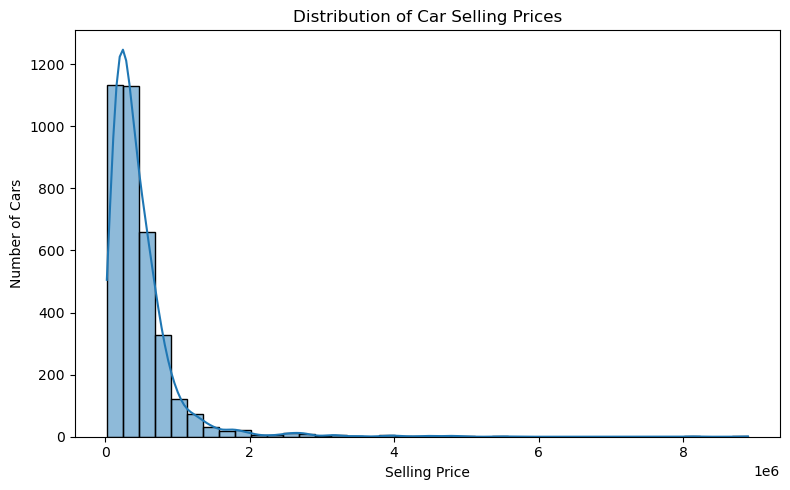

In [ ]:
# Distribution of selling prices
plt.figure(figsize=(8, 5))
sns.histplot(df["selling_price"], bins=40, kde=True)
plt.title("Distribution of Car Selling Prices")
plt.xlabel("Selling Price")
plt.ylabel("Number of Cars")
plt.tight_layout()
plt.savefig("outputs/price_distribution.png")
plt.show()

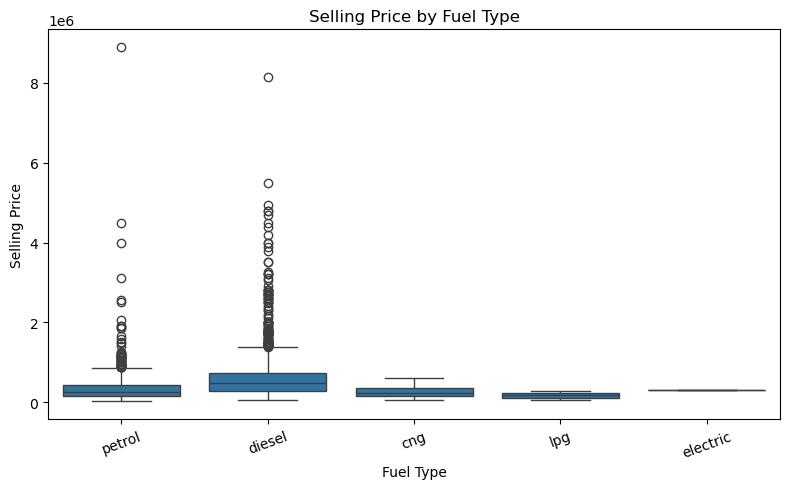

In [7]:
# Selling price by fuel type
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="fuel", y="selling_price")
plt.title("Selling Price by Fuel Type")
plt.xlabel("Fuel Type")
plt.ylabel("Selling Price")
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig("outputs/price_by_fuel.png")
plt.show()

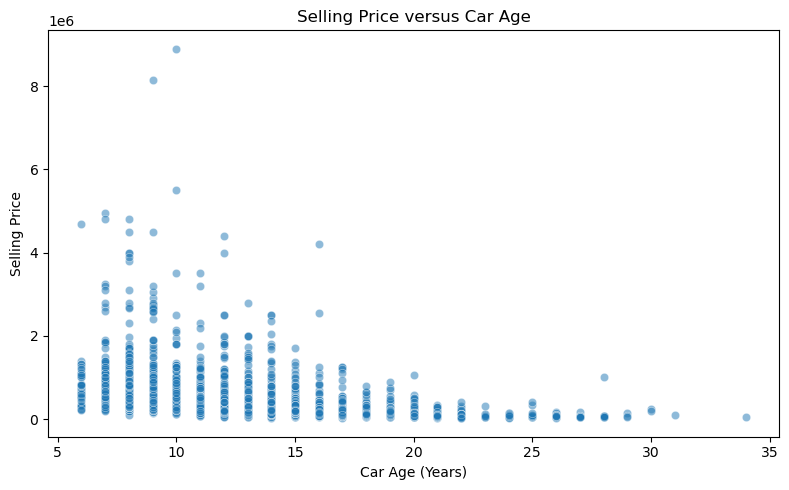

In [8]:
# Selling price versus car age
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df,
    x="car_age",
    y="selling_price",
    alpha=0.5)
plt.title("Selling Price versus Car Age")
plt.xlabel("Car Age (Years)")
plt.ylabel("Selling Price")
plt.tight_layout()
plt.savefig("outputs/price_vs_age.png")
plt.show()

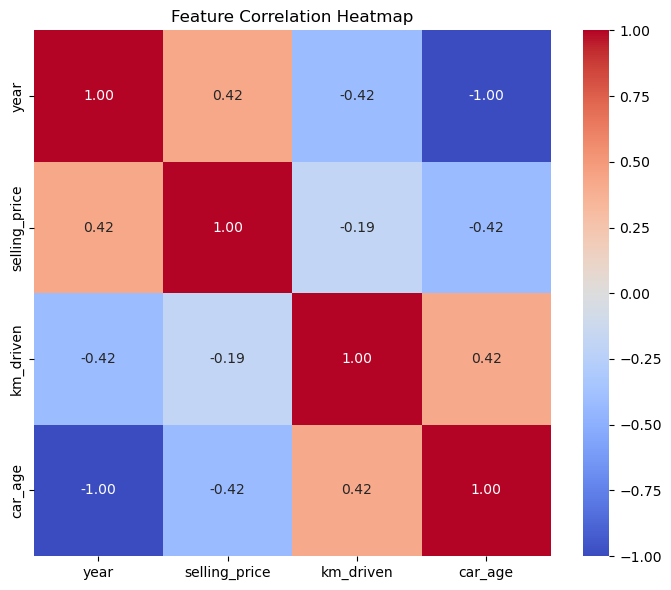

In [10]:
# Correlation heatmap
numeric_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(7, 6))
sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.savefig("outputs/correlation_heatmap.png")
plt.show()

# Selecting feature & target

In [11]:
# Features used to predict the price
X = df[["km_driven",
        "car_age",
        "brand",
        "fuel",
        "seller_type",
        "transmission",
        "owner"]]

# Target variable
y = df["selling_price"]

numeric_features = ["km_driven","car_age"]

categorical_features = ["brand","fuel","seller_type","transmission","owner"]

print("\nFEATURE DATA:")
print(X.head())

print("\nTARGET DATA:")
print(y.head())


FEATURE DATA:
   km_driven  car_age    brand    fuel seller_type transmission         owner
0      70000       19   maruti  petrol  individual       manual   first owner
1      50000       19   maruti  petrol  individual       manual   first owner
2     100000       14  hyundai  diesel  individual       manual   first owner
3      46000        9   datsun  petrol  individual       manual   first owner
4     141000       12    honda  diesel  individual       manual  second owner

TARGET DATA:
0     60000
1    135000
2    600000
3    250000
4    450000
Name: selling_price, dtype: int64


# Preprocessing

In [12]:
# Fill missing numerical values with the median
# StandardScaler puts numerical features on a comparable scale
numeric_transformer = Pipeline(
    steps=[("imputer", SimpleImputer(strategy="median")),("scaler", StandardScaler())])

# Fill missing categories with the most frequent value
# OneHotEncoder converts categories into numerical columns
categorical_transformer = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder",OneHotEncoder(handle_unknown="ignore"))])

# Apply the correct preprocessing to each column group
preprocessor = ColumnTransformer(transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)])

# Train-Test split

In [13]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.20,random_state=42)

print("\nTRAINING ROWS:", X_train.shape[0])
print("TESTING ROWS:", X_test.shape[0])


TRAINING ROWS: 2861
TESTING ROWS: 716


# Modeling

In [14]:
#  Linear Regression
linear_model = Pipeline(steps=[("preprocessor", preprocessor),("regressor", LinearRegression())])

In [15]:
linear_model

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['km_driven', 'car_age']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['brand', 'fuel',
                                                   'seller_type',
                                                   'transmission',
                                                   'owner'])])),
                ('regressor', LinearRegression())])

In [16]:
# Random Forest Regressor
random_forest_model = Pipeline(steps=[("preprocessor", preprocessor),
        ("regressor",RandomForestRegressor(n_estimators=200,random_state=42,n_jobs=-1))])

random_forest_model

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['km_driven', 'car_age']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['brand', 'fuel',
                                                   'seller_type',
                                                   'transmission',
                                                   'owner'])])),
                ('regressor',
                 RandomForestRegressor(n_estimators=200, n_jobs=-1,
                                       random_state=42))])

# Train & Evaluate models

In [17]:
models = {"Linear Regression": linear_model,"Random Forest": random_forest_model}

results = []
trained_models = {}

for model_name, model in models.items():

    print(f"\nTraining {model_name}...")

    # Learn patterns from training data
    model.fit(X_train, y_train)

    # Predict prices for unseen test data
    predictions = model.predict(X_test)

    # Calculate evaluation metrics
    mae = mean_absolute_error(y_test, predictions)

    rmse = np.sqrt(mean_squared_error(y_test, predictions))

    r2 = r2_score(y_test, predictions)

    results.append({
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2})

    trained_models[model_name] = model

    print("MAE:", round(mae, 2))
    print("RMSE:", round(rmse, 2))
    print("R2 Score:", round(r2, 4))


Training Linear Regression...
MAE: 179642.85
RMSE: 384722.68
R2 Score: 0.5405

Training Random Forest...
MAE: 157865.78
RMSE: 364617.51
R2 Score: 0.5873


# Compare models

In [18]:
results_df = pd.DataFrame(results)

print("\nMODEL COMPARISON:")
print(results_df.to_string(index=False))

# Select the model with the highest R2 score
best_model_name = results_df.loc[results_df["R2 Score"].idxmax(),"Model"]

best_model = trained_models[best_model_name]

print("\nBEST MODEL:", best_model_name)


MODEL COMPARISON:
            Model           MAE          RMSE  R2 Score
Linear Regression 179642.853716 384722.676287  0.540527
    Random Forest 157865.782061 364617.511612  0.587295

BEST MODEL: Random Forest


# Feature importance


TOP 15 IMPORTANT FEATURES:
                    Feature  Importance
               num__car_age    0.221682
cat__transmission_automatic    0.135193
             num__km_driven    0.132800
   cat__transmission_manual    0.112385
           cat__fuel_diesel    0.074429
            cat__brand_audi    0.048499
           cat__fuel_petrol    0.041619
            cat__brand_land    0.040030
          cat__brand_toyota    0.036830
             cat__brand_bmw    0.014570
    cat__seller_type_dealer    0.011445
   cat__brand_mercedes-benz    0.010547
          cat__brand_jaguar    0.010435
          cat__brand_maruti    0.010068
cat__seller_type_individual    0.009236


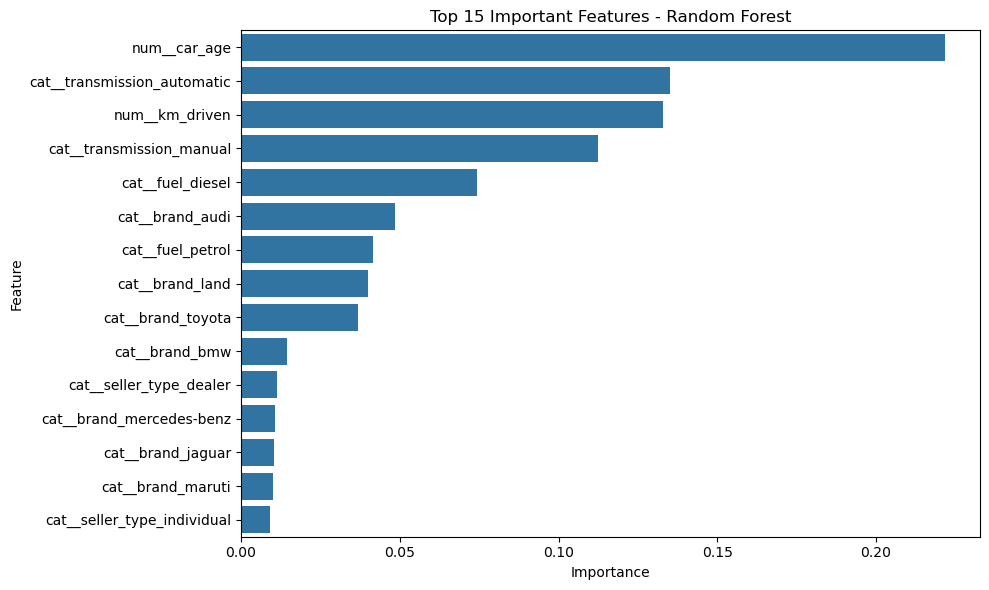

In [20]:
# Random Forest provides feature importance values
rf_model = trained_models["Random Forest"]

feature_names = (rf_model.named_steps["preprocessor"].get_feature_names_out())

importance_values = (rf_model.named_steps["regressor"].feature_importances_)

importance_df = pd.DataFrame({"Feature": feature_names,"Importance": importance_values})

importance_df = importance_df.sort_values(by="Importance",ascending=False)

print("\nTOP 15 IMPORTANT FEATURES:")
print(importance_df.head(15).to_string(index=False))


plt.figure(figsize=(10, 6))
sns.barplot(
    data=importance_df.head(15),
    x="Importance",
    y="Feature"
)
plt.title("Top 15 Important Features - Random Forest")
plt.tight_layout()
plt.savefig("outputs/feature_importance.png")
plt.show()

# Testing model

In [21]:
sample_car = pd.DataFrame([{
    "km_driven": 45000,
    "car_age": 5,
    "brand": "maruti",
    "fuel": "diesel",
    "seller_type": "individual",
    "transmission": "manual",
    "owner": "first owner"}])

predicted_price = best_model.predict(sample_car)[0]

print("\nSAMPLE CAR DETAILS:")
print(sample_car)

print("\nPREDICTED SELLING PRICE:")
print(f"Rs. {predicted_price:,.2f}")


SAMPLE CAR DETAILS:
   km_driven  car_age   brand    fuel seller_type transmission        owner
0      45000        5  maruti  diesel  individual       manual  first owner

PREDICTED SELLING PRICE:
Rs. 682,274.99


# Save model

In [22]:
import pickle

with open("car_model.pkl", "wb") as file:
    pickle.dump(best_model, file)

print("Model saved successfully!")

Model saved successfully!
